In [1]:
import onnxruntime as ort
import numpy as np
import json
import uproot
import pandas as pd
import matplotlib.pyplot as plt
import mplhep
from sklearn import metrics
from scipy.integrate import simpson
from scipy.integrate import trapezoid
from scipy.stats import distributions
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import KFold
from scipy.stats import chisquare
import xgboost 
import pickle
import json
from scipy.stats import chisquare
import warnings
from collections import defaultdict #for feature imp avg
import seaborn as sns
from pprint import pprint
from matplotlib.ticker import FuncFormatter  #for y-axis scaling for histograms
import matplotlib.ticker as mtick

In [2]:
uproot.__version__, pd.__version__, np.__version__, xgboost.__version__

('4.3.7', '1.5.3', '1.23.5', '2.0.2')

In [3]:
# Initialize the counter
if 'execution_count' not in globals():
    execution_count = 0


In [4]:
mplhep.style.use('ATLAS')
nbins = 10

In [5]:
# KS Test
def ks_weighted(data1, data2, wei1, wei2, alternative='two-sided'):
    data1 = np.array(data1)
    data2 = np.array(data2)
    wei1 = np.array(wei1)
    wei2 = np.array(wei2)
    
    ix1 = np.argsort(data1)
    ix2 = np.argsort(data2)
    data1 = data1[ix1]
    data2 = data2[ix2]
    wei1 = wei1[ix1]
    wei2 = wei2[ix2]
    data = np.concatenate([data1, data2])
    cwei1 = np.hstack([0, np.cumsum(wei1)/sum(wei1)])
    cwei2 = np.hstack([0, np.cumsum(wei2)/sum(wei2)])
    cdf1we = cwei1[np.searchsorted(data1, data, side='right')]
    cdf2we = cwei2[np.searchsorted(data2, data, side='right')]
    d = np.max(np.abs(cdf1we - cdf2we))
    # calculate p-value
    n1 = data1.shape[0]
    n2 = data2.shape[0]
    m, n = sorted([float(n1), float(n2)], reverse=True)
    en = m * n / (m + n)
    if alternative == 'two-sided':
        prob = distributions.kstwo.sf(d, np.round(en))
    else:
        z = np.sqrt(en) * d
        # Use Hodges' suggested approximation Eqn 5.3
        # Requires m to be the larger of (n1, n2)
        expt = -2 * z**2 - 2 * z * (m + 2*n)/np.sqrt(m*n*(m+n))/3.0
        prob = np.exp(expt)
    return d, prob

In [54]:
# Set of variables for WP85

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets85', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb85_closest[:,0]',
                'ph_mphb85_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph'
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 2 times.


In [7]:
len(feature_cols)

19

In [8]:
cols = feature_cols+['eventNumber','weight','mcChannelNumber']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [39]:
df_sig_85 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets85>=1)',library="pd",aliases=aliases)

df_sig_70 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)
df_bkg_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_*.root:nominal','/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(event_nbjets70>=1)',library="pd",aliases=aliases)


In [40]:
len(df_sig_85), len(df_bkg_85), len(df_sig_70), len(df_bkg_70)

# WP 70: 323900, 3959 


(358887, 5855, 323900, 3959)

In [41]:
df_bkg_prompt_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)

######################



df_bkg_prompt_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)


######################



df_bkg_prompt_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_prompt_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)


df_bkg_fakes_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_fakes_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)




######################

df_bkg_prompt_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_prompt_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


df_bkg_fakes_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_fakes_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


In [42]:
print('For tty prod NLO (prompts at 85 and 70): ', len(df_bkg_prompt_ttyprodNLO_85), len(df_bkg_prompt_ttyprodNLO_70))
print('For tty prod NLO (fakes at 85 and 70): ', len(df_bkg_fakes_ttyprodNLO_85), len(df_bkg_fakes_ttyprodNLO_70))

print('For tty dec LO (prompts at 85 and 70): ', len(df_bkg_prompt_ttydecLO_85), len(df_bkg_prompt_ttydecLO_70))
print('For tty dec LO (fakes at 85 and 70): ', len(df_bkg_fakes_ttydecLO_85), len(df_bkg_fakes_ttydecLO_70))


print('For Wyy (prompts at 85 and 70): ',len(df_bkg_prompt_Wyy_85), len(df_bkg_prompt_Wyy_70))
print('For Wyy (fakes at 85 and 70): ',len(df_bkg_fakes_Wyy_85), len(df_bkg_fakes_Wyy_70))
print('For Zyy (prompts at 85 and 70): ',len(df_bkg_prompt_Zyy_85), len(df_bkg_prompt_Zyy_70))
print('For Zyy (fakes at 85 and 70): ',len(df_bkg_fakes_Zyy_85), len(df_bkg_fakes_Zyy_70))

For tty prod NLO (prompts at 85 and 70):  222 203
For tty prod NLO (fakes at 85 and 70):  1928 1748
For tty dec LO (prompts at 85 and 70):  141 126
For tty dec LO (fakes at 85 and 70):  1036 942
For Wyy (prompts at 85 and 70):  368 130
For Wyy (fakes at 85 and 70):  0 0
For Zyy (prompts at 85 and 70):  2073 774
For Zyy (fakes at 85 and 70):  87 36


In [43]:
data = [
    ["tty prod NLO", "Prompts", len(df_bkg_prompt_ttyprodNLO_85), len(df_bkg_prompt_ttyprodNLO_70)],
    ["tty prod NLO", "Fakes", len(df_bkg_fakes_ttyprodNLO_85), len(df_bkg_fakes_ttyprodNLO_70)],
    ["tty dec LO", "Prompts", len(df_bkg_prompt_ttydecLO_85), len(df_bkg_prompt_ttydecLO_70)],
    ["tty dec LO", "Fakes", len(df_bkg_fakes_ttydecLO_85), len(df_bkg_fakes_ttydecLO_70)],
    ["Wyy", "Prompts", len(df_bkg_prompt_Wyy_85), len(df_bkg_prompt_Wyy_70)],
    ["Wyy", "Fakes", len(df_bkg_fakes_Wyy_85), len(df_bkg_fakes_Wyy_70)],
    ["Zyy", "Prompts", len(df_bkg_prompt_Zyy_85), len(df_bkg_prompt_Zyy_70)],
    ["Zyy", "Fakes", len(df_bkg_fakes_Zyy_85), len(df_bkg_fakes_Zyy_70)],
]

# Print the data in a tabular format
print(f"{'Process':<15} {'Type':<10} {'85 Cut':<10} {'70 Cut':<10}")
print("-" * 45)
for row in data:
    print(f"{row[0]:<15} {row[1]:<10} {row[2]:<10} {row[3]:<10}")

print("-" * 45)

print(f"{'Total:':<25} {len(df_bkg_85):<10} {len(df_bkg_70):<10}")

Process         Type       85 Cut     70 Cut    
---------------------------------------------
tty prod NLO    Prompts    222        203       
tty prod NLO    Fakes      1928       1748      
tty dec LO      Prompts    141        126       
tty dec LO      Fakes      1036       942       
Wyy             Prompts    368        130       
Wyy             Fakes      0          0         
Zyy             Prompts    2073       774       
Zyy             Fakes      87         36        
---------------------------------------------
Total:                    5855       3959      


In [44]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())


count    222.000000
mean       0.007957
std        0.016986
min       -0.026761
25%       -0.010580
50%        0.015828
75%        0.021102
max        0.027507
Name: weight, dtype: float64


In [45]:
# Reweight per process:
df_bkg_prompt_ttyprodNLO_85['weight'] *= len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)
df_bkg_fakes_ttyprodNLO_85['weight'] *= len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)
df_bkg_prompt_ttydecLO_85['weight'] *= len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)
df_bkg_fakes_ttydecLO_85['weight'] *= len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)
df_bkg_prompt_Wyy_85['weight'] *= len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)
#df_bkg_fakes_Wyy_85['weight'] *= len(df_bkg_fakes_Wyy_70)/len(df_bkg_fakes_Wyy_85)
df_bkg_prompt_Zyy_85['weight'] *= len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)
df_bkg_fakes_Zyy_85['weight'] *= len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)



In [46]:
df_bkg_prompt_ttyprodNLO_85['weight']
print(df_bkg_prompt_ttyprodNLO_85['weight'].describe())


count    222.000000
mean       0.007276
std        0.015533
min       -0.024470
25%       -0.009675
50%        0.014474
75%        0.019296
max        0.025153
Name: weight, dtype: float64


In [47]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_prompt_85_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_85, df_bkg_prompt_ttydecLO_85, df_bkg_prompt_Wyy_85, df_bkg_prompt_Zyy_85], ignore_index=False)
len(df_bkg_prompt_85_reweighted)

2804

In [48]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_fakes_85_reweighted = pd.concat([df_bkg_fakes_ttyprodNLO_85, df_bkg_fakes_ttydecLO_85, df_bkg_fakes_Wyy_85, df_bkg_fakes_Zyy_85], ignore_index=False)
len(df_bkg_fakes_85_reweighted)

3051

In [49]:
df_bkg_85_reweighted = pd.concat([df_bkg_prompt_85_reweighted, df_bkg_fakes_85_reweighted], ignore_index=False)

In [22]:
df_sig_85['ph_conversion_type[:,0]'], df_bkg_85_reweighted['ph_conversion_type[:,0]']


(entry
 0         0
 1         3
 2         0
 3         3
 4         0
          ..
 361992    0
 361993    0
 361994    0
 361995    0
 361996    0
 Name: ph_conversion_type[:,0], Length: 358887, dtype: int32,
 entry
 9       3
 10      0
 39      0
 42      1
 43      3
        ..
 1888    0
 1896    3
 1910    3
 1923    0
 1945    0
 Name: ph_conversion_type[:,0], Length: 5855, dtype: int32)

In [23]:
df_sig_85['ph_conversion_type[:,0]'] = np.where(df_sig_85['ph_conversion_type[:,0]'] > 0, 1,0)

df_bkg_85_reweighted['ph_conversion_type[:,0]'] = np.where(df_bkg_85_reweighted['ph_conversion_type[:,0]'] > 0, 1,0)

In [24]:
df_sig_85['ph_conversion_type[:,0]'], df_bkg_85_reweighted['ph_conversion_type[:,0]']


(entry
 0         0
 1         1
 2         0
 3         1
 4         0
          ..
 361992    0
 361993    0
 361994    0
 361995    0
 361996    0
 Name: ph_conversion_type[:,0], Length: 358887, dtype: int64,
 entry
 9       1
 10      0
 39      0
 42      1
 43      1
        ..
 1888    0
 1896    1
 1910    1
 1923    0
 1945    0
 Name: ph_conversion_type[:,0], Length: 5855, dtype: int64)

In [25]:
len(df_bkg_85_reweighted)

5855

In [26]:
mplhep.style.use('ATLAS')

# Training and Evaluation with WP85 (bkg reweighted to match WP70 statistics)

In [50]:
n_estimators = 100

In [51]:
df_sig_85_reweighted = df_sig_85

In [52]:
# SINGLE MODEL  : Using XGB Classifier
# with WP85 and NOT reweighted to WP70
models_85_reweighted = []
nfolds = 4
scores_train,scores_test = [],[]
testloss_85_reweighted = {fold:[] for fold in range(nfolds)}
trainloss_85_reweighted = {fold:[] for fold in range(nfolds)}


for fold in range(nfolds):
    print("-------------------------------------------------------------------------------")
    print(f'Doing it for fold: {fold}')
    X_sig_train = df_sig_85_reweighted[feature_cols][df_sig_85_reweighted['eventNumber']%nfolds != fold]
    w_sig_train = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%nfolds != fold]
    
    X_sig_test = df_sig_85_reweighted[feature_cols][df_sig_85_reweighted['eventNumber']%nfolds == fold]
    w_sig_test = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%nfolds == fold]
    
    X_bkg_train = df_bkg_85_reweighted[feature_cols][df_bkg_85_reweighted['eventNumber']%nfolds != fold]
    w_bkg_train = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%nfolds != fold]

    X_bkg_test = df_bkg_85_reweighted[feature_cols][df_bkg_85_reweighted['eventNumber']%nfolds == fold]
    w_bkg_test = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%nfolds == fold]
    
    print('Length of training and testing datasets loaded:')
    print(f'Signal training stats: {len(X_sig_train)}')
    print(f'Background training stats: {len(X_bkg_train)}')
    
    print(f'Signal testing stats: {len(X_sig_test)}')
    print(f'Background testing stats: {len(X_bkg_test)}')
    
    
    # Setting up the concatentated datasets for training and testing
    y_train =  np.concatenate([np.ones_like(w_sig_train),np.zeros_like(w_bkg_train)])
    X_train =  np.concatenate([X_sig_train,X_bkg_train])
    w_train =  np.concatenate([w_sig_train,w_bkg_train])
    y_test  =  np.concatenate([np.ones_like(w_sig_test),np.zeros_like(w_bkg_test)])
    X_test  =  np.concatenate([X_sig_test,X_bkg_test])
    w_test  =  np.concatenate([w_sig_test,w_bkg_test])
    
    print('Total datasets:')
    print(f'Signal+Background training: {len(X_train)}')
    print(f'Signal+Background testing: {len(X_test)}')
    
    #model = XGBClassifier(tree_method="hist",device = "cuda", n_estimators=80, verbosity=2) #, learning_rate=0.18, n_estimators=240, max_depth=3)
    
    # Note: No scale_pos_weight reweighting being used
    model = XGBClassifier(tree_method="hist", verbosity=2, n_estimators=n_estimators)
    model.fit(X_train, y_train, sample_weight=np.abs(w_train))
    models_85_reweighted.append(model)
    print(f'Model {fold}:', models_85_reweighted[fold])
    
    #Calculating scores
    scores_train.append(model.score(X_train,y_train,sample_weight=np.abs(w_train)))
    scores_test.append(model.score(X_test,y_test,sample_weight=np.abs(w_test))) 
    print(f'Training scores {fold}:', scores_train)
    print(f'Testing scores {fold}:', scores_test)
       
                       
    #For loss curve
    n_boosters = len(models_85_reweighted[fold].get_booster().get_dump(dump_format='json'))
    print('Number of boosters in the model:', n_boosters)
    for i in range(n_boosters):
        # ypred contains the predicted probabilities of class 1 (positive class i.e. [:,1]) for all samples in X_train, based on the model trained on the specified iteration range of 1 till i+1 estimators/boosters 
        ypred = models_85_reweighted[fold].predict_proba(X_train, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_train, ypred, sample_weight=np.abs(w_train))
        trainloss_85_reweighted[fold].append(loss)
        # similarly for testing
        ypred = models_85_reweighted[fold].predict_proba(X_test, iteration_range=(1,i+1))[:,1]
        loss = metrics.log_loss(y_test, ypred, sample_weight=np.abs(w_test))
        testloss_85_reweighted[fold].append(loss)
        
 
    #with open(F'CI_test_BDT_binary_Classifier_Classification-BDT_WP85reweightedtoWP70PerProcess_Model{execution_count}_Fold{fold}.pkl', 'wb') as f:
    #    pickle.dump(model, f)
    

-------------------------------------------------------------------------------
Doing it for fold: 0
Length of training and testing datasets loaded:
Signal training stats: 269250
Background training stats: 4403
Signal testing stats: 89637
Background testing stats: 1452
Total datasets:
Signal+Background training: 273653
Signal+Background testing: 91089
Model 0: XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
        

In [30]:
mplhep.style.use('ATLAS')    


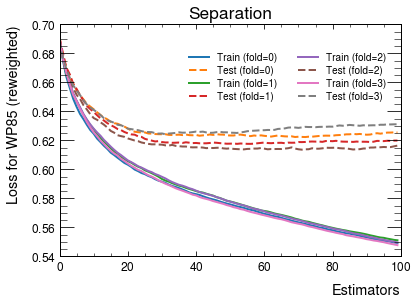

In [53]:
#mplhep.style.use('ATLAS')    
    
# Plotting the results For WP85 only
fig, ax = plt.subplots()
for fold in range(nfolds):
    #estimators = range(0, 100)
    estimators = range(0, n_estimators)
    ax.plot(estimators, trainloss_85_reweighted[fold], label=f'Train ({fold=})')
    ax.plot(estimators, testloss_85_reweighted[fold], label=f'Test ({fold=})', linestyle='--')

ax.legend(title=' ',ncols=2)
ax.set_title('')
#mplhep.atlas.label('Internal', data=False, ax=ax)   # true to remove Simulation
ax.set_title('Separation')
ax.set_xlabel('Estimators')
ax.set_ylabel('Loss for WP85 (reweighted)')
#plt.savefig(f'loss_curve_model7_85To70PerProcess.pdf')

plt.show()

In [32]:
X_sig_85_reweighted = df_sig_85_reweighted[feature_cols].to_numpy().astype(np.float32) 
X_bkg_85_reweighted = df_bkg_85_reweighted[feature_cols].to_numpy().astype(np.float32) 

results_sig_list = []
results_bkg_list = []

results_sig_list = [model.predict_proba(X_sig_85_reweighted)[:,1] for model in models_85_reweighted]   #array of bdt scores
results_bkg_list = [model.predict_proba(X_bkg_85_reweighted)[:,1] for model in models_85_reweighted]   #array of bdt scores

print('Arrays for BDT scroes:')
print('Sig: ',results_sig_list)
print('Bkg: ',results_bkg_list)
print("Length: ", len(results_sig_list))

# Separate into folds
condlist_sig = [df_sig_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_sig_85_reweighted = np.select(condlist_sig, results_sig_list)

condlist_bkg = [df_bkg_85_reweighted['eventNumber']%nfolds == fold for fold in range(nfolds)]
results_bkg_85_reweighted = np.select(condlist_bkg, results_bkg_list)

print('Fold separated arrays for BDT scroes:')
results_sig_85_reweighted, results_bkg_85_reweighted
print("Length sig: ", len(results_sig_85_reweighted))
print("Length bkg: ", len(results_bkg_85_reweighted))

Arrays for BDT scroes:
Sig:  [array([0.43894583, 0.6921752 , 0.7262736 , ..., 0.71720815, 0.7432094 ,
       0.5564333 ], dtype=float32), array([0.41942427, 0.5988035 , 0.7111147 , ..., 0.7111218 , 0.72099125,
       0.5544311 ], dtype=float32), array([0.38362232, 0.7068762 , 0.7847929 , ..., 0.7434877 , 0.6390332 ,
       0.5489199 ], dtype=float32), array([0.44809896, 0.6319379 , 0.63597393, ..., 0.6544431 , 0.7031191 ,
       0.49408787], dtype=float32)]
Bkg:  [array([0.3422129 , 0.34599915, 0.32624206, ..., 0.4456382 , 0.47121093,
       0.15362734], dtype=float32), array([0.26144445, 0.43596444, 0.37763306, ..., 0.40544358, 0.36822814,
       0.18072876], dtype=float32), array([0.24880584, 0.38074017, 0.4016994 , ..., 0.33341366, 0.37414685,
       0.17644104], dtype=float32), array([0.3469539 , 0.36437392, 0.21666569, ..., 0.3760439 , 0.43019006,
       0.21446298], dtype=float32)]
Length:  4
Fold separated arrays for BDT scroes:
Length sig:  358887
Length bkg:  5855


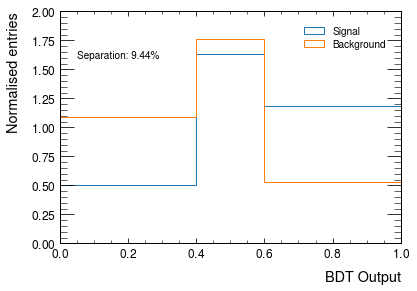

In [33]:

# Define custom bin edges
custom_bins = [0, 0.4, 0.6, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig_85_reweighted, weights=df_sig_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg_85_reweighted, weights=df_bkg_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_fittedbins.pdf')
plt.legend()


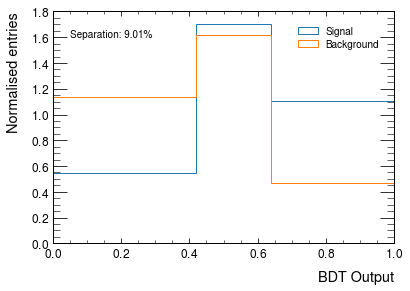

In [34]:
# Define custom bin edges
custom_bins = [0, 0.42, 0.639, 1]

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig_85_reweighted, weights=df_sig_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg_85_reweighted, weights=df_bkg_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_Model7_fittedbins_85To70PerProcess.pdf')
plt.legend()


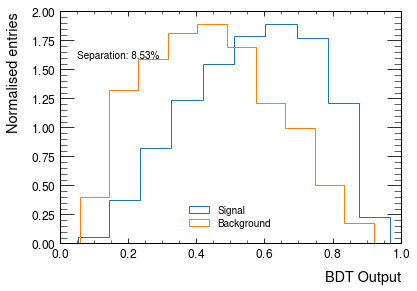

In [35]:

# Define custom bin edges
custom_bins = 10

# Histogram plotting
bc_sig, bin_edges, _ = plt.hist(results_sig_85_reweighted, weights=df_sig_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Signal')
bc_bkg, _, _ = plt.hist(results_bkg_85_reweighted, weights=df_bkg_85_reweighted['weight'], bins=custom_bins, histtype='step', density=True, label='Background')

# Calculate bin widths and separation
bin_widths = np.diff(bin_edges)
separation = 0.5 * np.sum(np.nan_to_num(((bc_sig - bc_bkg) ** 2) / (bc_sig + bc_bkg)) * bin_widths)

# Plotting details
plt.legend(loc='upper right')
plt.xlabel('BDT Output')
plt.ylabel('Normalised entries')
plt.text(x=0.05, y=1.6, s=f'Separation: {separation*100:.2f}%')
#plt.savefig(f'separation_Model7_10bins_85To70PerProcess.pdf')
plt.legend()


(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

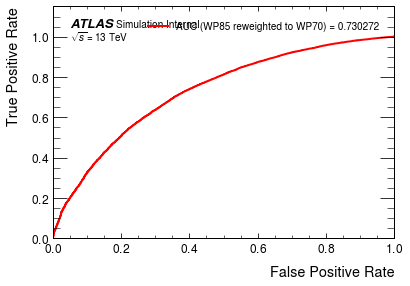

In [36]:
# Aggregate AUC 

scores_85_reweighted = np.concatenate([results_sig_85_reweighted, results_bkg_85_reweighted])
y_85_reweighted = np.concatenate([np.ones_like(results_sig_85_reweighted), np.zeros_like(results_bkg_85_reweighted)])

fpr_85_reweighted, tpr_85_reweighted, thresholds_85_reweighted = metrics.roc_curve(y_85_reweighted, scores_85_reweighted, pos_label=1)
AUC_85_reweighted = metrics.roc_auc_score(y_85_reweighted, scores_85_reweighted)

plt.plot(fpr_85_reweighted,tpr_85_reweighted,label=F'AUC (WP85 reweighted to WP70) = {AUC_85_reweighted:.6f}', color='red')
plt.legend(loc = 'upper right', fontsize=10)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

# Save the data to a file
#np.savez('roc_data_85_reweighted_perprocess.npz', fpr=fpr_85_reweighted, tpr=tpr_85_reweighted, thresholds=thresholds_85_reweighted, auc=AUC_85_reweighted)
#print("Data saved to 'roc_data_85_reweighted_perprocess.npz'")

######################################################################################################################################

## Redo training because of changed feature_cols OR try to use the npz file as it has stored AUC values from WP70 run on different ipynb file

In [102]:
data = np.load('roc_data_70.npz')
fpr_70 = data['fpr']
tpr_70 = data['tpr']
thresholds_70 = data['thresholds']
AUC_70 = data['auc']
print(f"Loaded data: AUC = {AUC_70}")


data = np.load('roc_data_85.npz')
fpr_85 = data['fpr']
tpr_85 = data['tpr']
thresholds_85 = data['thresholds']
AUC_85 = data['auc']
print(f"Loaded data: AUC = {AUC_85}")




data = np.load('roc_data_85_reweighted.npz')
fpr_85_reweighted = data['fpr']
tpr_85_reweighted = data['tpr']
thresholds_85_reweighted = data['thresholds']
AUC_85_reweighted = data['auc']
print(f"Loaded data: AUC = {AUC_85_reweighted}")




data = np.load('roc_data_85_reweighted_perprocess.npz')
fpr_85_reweighted_perprocess = data['fpr']
tpr_85_reweighted_perprocess = data['tpr']
thresholds_85_reweighted_perprocess = data['thresholds']
AUC_85_reweighted_perprocess = data['auc']
print(f"Loaded data: AUC = {AUC_85_reweighted_perprocess}")



Loaded data: AUC = 0.6948133504263093
Loaded data: AUC = 0.758648874245013
Loaded data: AUC = 0.7458934333600129
Loaded data: AUC = 0.7367951305625539


# All in one AUC

(exptext: Custom Text(0.05, 0.95, 'ATLAS'),
 expsuffix: Custom Text(0.05, 0.955, 'Simulation Internal'),
 expsuffix: Custom Text(0.05, 0.95, '$\\sqrt{s} = \\mathrm{13\\ TeV}$'))

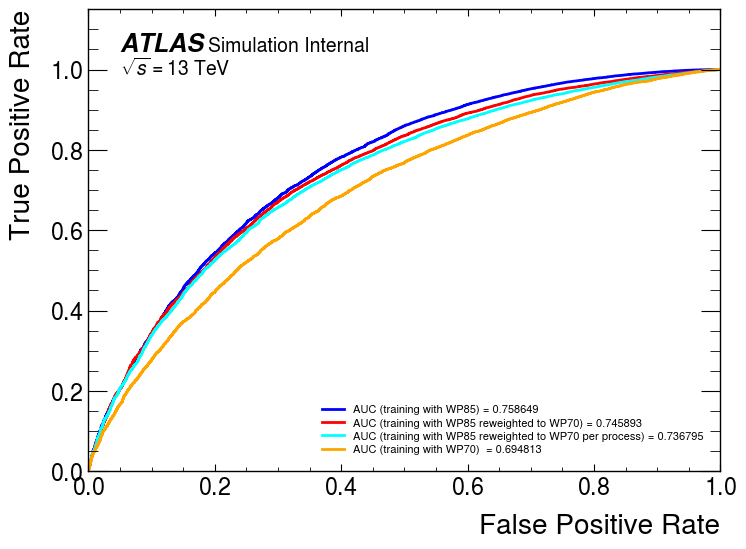

In [107]:
# AUC's comparison:


plt.plot(fpr_85,tpr_85,label=F'AUC (training with WP85) = {AUC_85:.6f}', color='blue')
plt.plot(fpr_85_reweighted,tpr_85_reweighted,label=F'AUC (training with WP85 reweighted to WP70) = {AUC_85_reweighted:.6f}', color='red')
plt.plot(fpr_85_reweighted_perprocess,tpr_85_reweighted_perprocess,label=F'AUC (training with WP85 reweighted to WP70 per process) = {AUC_85_reweighted_perprocess:.6f}', color='cyan')
plt.plot(fpr_70,tpr_70,label=F'AUC (training with WP70)  = {AUC_70:.6f}', color='orange')


plt.legend(loc = 'lower right', fontsize=8)
plt.xlim(0,1)
plt.ylim(0,1.15)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
mplhep.atlas.label('Internal', data=False)

In [ ]:
# Feature importance

Features with Average Importance (Descending):
Feature Name: ph_conversion_type[:,0], Average Importance: 0.19142555445432663
Feature Name: ph_conversion_type[:,1], Average Importance: 0.1801520437002182
Feature Name: jet_tagWeightBin_DL1r_Continuous_Max, Average Importance: 0.12031416222453117
Feature Name: dr_lep_ph1, Average Importance: 0.06954778917133808
Feature Name: ph_mlph_closest[:,1], Average Importance: 0.0505231898277998
Feature Name: event_nbjets85, Average Importance: 0.04407121241092682
Feature Name: dr_lep_ph0, Average Importance: 0.03615958895534277
Feature Name: ph_eta[:,1], Average Importance: 0.03570959158241749
Feature Name: ph_mphb85_closest[:,1], Average Importance: 0.0265093264169991
Feature Name: jet_pt[:,1], Average Importance: 0.026203166227787733
Feature Name: ph_mphb85_closest[:,0], Average Importance: 0.02526723174378276
Feature Name: jet_pt[:,0], Average Importance: 0.023904815316200256
Feature Name: dr_ph, Average Importance: 0.02386039635166526
Feature 

<Figure size 1200x800 with 0 Axes>

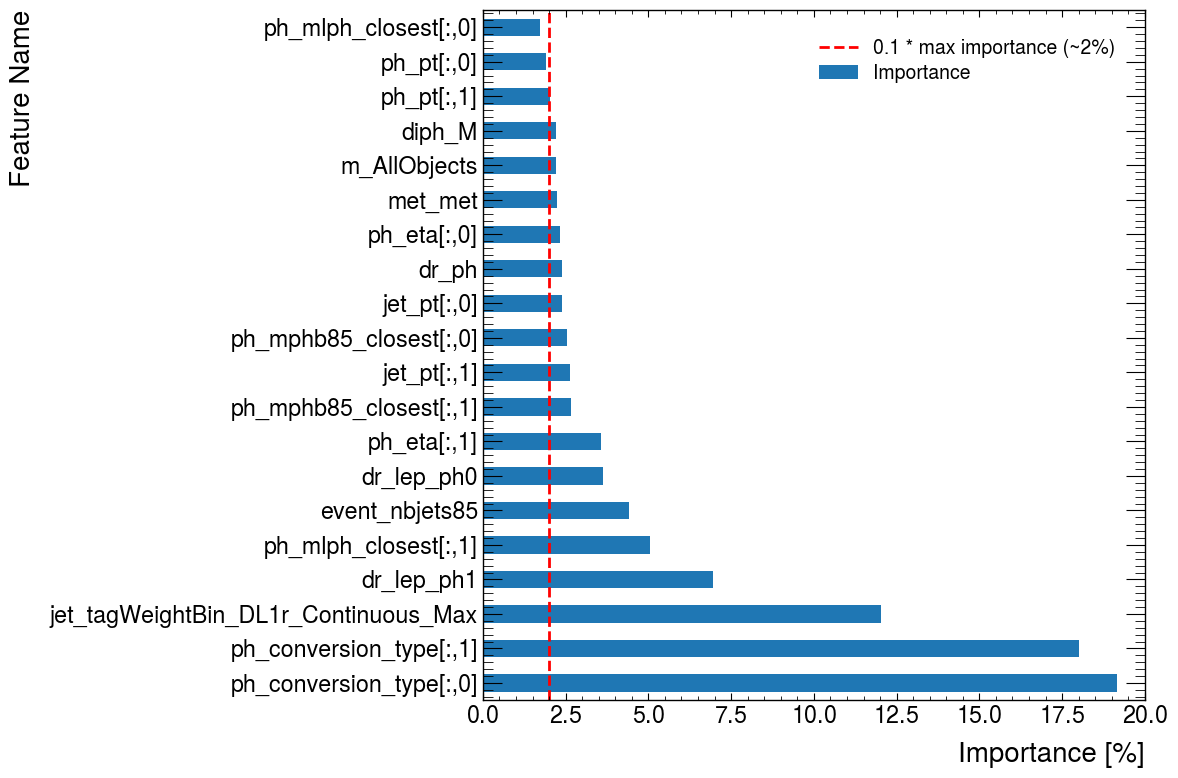

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

def average_feature_importances(models, feature_cols):
  """
  This function calculates the average importance for each feature across all folds/models.

  Args:
      models: A list of XGBoost classifier models.
      feature_cols: A list of feature column names.

  Returns:
      A dictionary containing feature name and its average importance across all folds.
  """
  # Initialize a dictionary to store average importance
  average_importances = {feature: 0.0 for feature in feature_cols}

  # Iterate through each model and accumulate importance for each feature
  for model in models_85_reweighted:
    importance_scores = model.feature_importances_  # Access feature importance attribute
    for feature, importance in zip(feature_cols, importance_scores):
      average_importances[feature] += importance

  # Calculate average importance by dividing by the total number of models
  num_models = len(models_85_reweighted)
  for feature in average_importances:
    average_importances[feature] /= num_models

  # Sort features by importance in descending order
  sorted_importances = sorted(average_importances.items(), key=lambda x: x[1], reverse=True)
  return sorted_importances

# Assuming models and feature_cols are available (replace with your actual data)
average_importances = average_feature_importances(models_85_reweighted, feature_cols)

# Print features with average importance (sorted by descending importance)
print("Features with Average Importance (Descending):")
for feature, importance in average_importances:
  print(f"Feature Name: {feature}, Average Importance: {importance}")

# Create DataFrame from sorted importance and plot as horizontal bar chart
importance_df = pd.DataFrame(average_importances, columns=['Feature', 'Importance'])
importance_df['Importance'] *= 100  # Scale importance to percentage

plt.figure(figsize=(12, 8))
importance_df.set_index('Feature').plot.barh(legend=False, figsize=(12, 8))
plt.xlabel('Importance [%]', fontsize=20)
plt.ylabel('Feature Name', fontsize=20)

# Optional: Add a threshold line (adjust threshold value as needed)
plt.axvline(2.0, color='red', linestyle='--', label='0.1 * max importance (~2%)')
plt.legend()
plt.savefig(f'Feature_importance_average_Model7_85To70PerProcess.pdf')

plt.tight_layout()
plt.show()


# KS tests

In [28]:
# Define the custom formatter function
def custom_formatter(x, pos):
    return f'{x * 0.1:.1f}'

[0.    0.42  0.639 1.   ]
-----------------------------------------------
0.5245168935944021 1.5473066615456261
0.5214698017855193 1.5910496950630986
4 3 3
Signal train histogram: [0.52451689 1.54730666 1.22117104]
Signal test histogram: [0.5214698 1.5910497 1.1981795]
Background train histogram: [1.23886336 1.38469379 0.48872424]
Background test histogram: [1.09667207 1.58477872 0.53277338]
-----------------------------------------------

Signal train errors: [0.03234894 0.04000296 0.04548433]
Signal test errors: [0.01864434 0.0234277  0.02600119]
Background train errors: [0.65472335 0.4693495  0.3415024 ]
Background test errors: [0.3537023 0.3760273 0.1800684]
-----------------------------------------------

Sig ratio:  [1.00584328 0.97250681 1.01918873]
Bkg ratio:  [1.12965707 0.87374582 0.91732105]

Sig Ratio uncertainties per bin:  [0.07170445 0.02893447 0.0439342 ]
Clipped errors: [0.07170445 0.02893447 0.0439342 ]
Clipped errors: [0.69940274 0.36151322 0.71203395]
[0.42  0.219 0

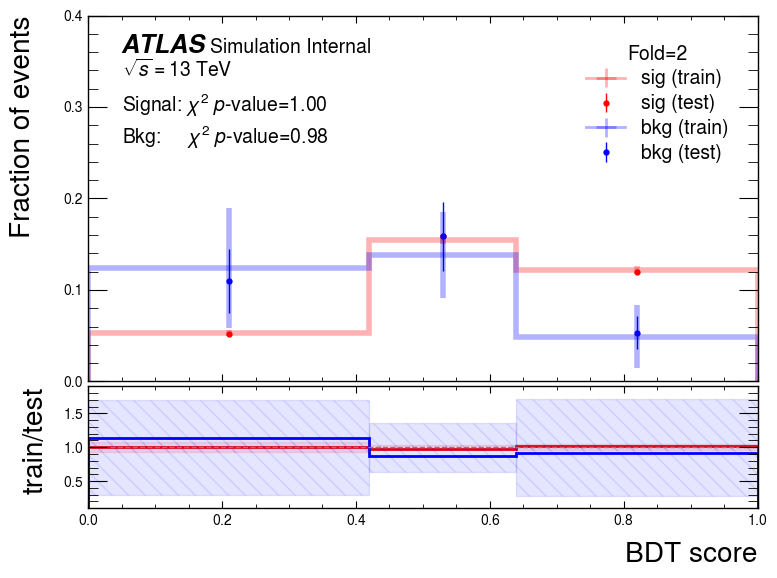

In [55]:
## !!!! KS test with fitted bins

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 2
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
custom_bins = [0, 0.420, 0.639, 1]


# Example dummy data and plots:
results_sig_fold_test = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

custom_bins = np.array([0, 0.420, 0.639, 1])


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
#fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model7_85To70PerProcess_fittedBins.png')

[0.    0.383 0.598 1.   ]
-----------------------------------------------
0.4585408063260577 1.4781125136433333
0.459060578547472 1.390131122106749
4 3 3
Signal train histogram: [0.45854081 1.47811251 1.2601609 ]
Signal test histogram: [0.45906058 1.39013112 1.30672042]
Background train histogram: [1.18001034 1.48679073 0.56814933]
Background test histogram: [1.10629575 1.75781537 0.49342891]
-----------------------------------------------

Signal train errors: [0.02886426 0.03874005 0.04876142]
Signal test errors: [0.01675092 0.02173886 0.02869247]
Background train errors: [0.6181145  0.545147   0.36049443]
Background test errors: [0.34508246 0.28554168 0.2338363 ]
-----------------------------------------------

Sig ratio:  [0.99886775 1.06328999 0.96436918]
Bkg ratio:  [1.0666319  0.84581734 1.15143097]

Sig Ratio uncertainties per bin:  [0.07267715 0.03245153 0.04290532]
Clipped errors: [0.07267715 0.03245153 0.04290532]
Clipped errors: [0.65028388 0.33920003 0.9118725 ]
[0.383 0.2

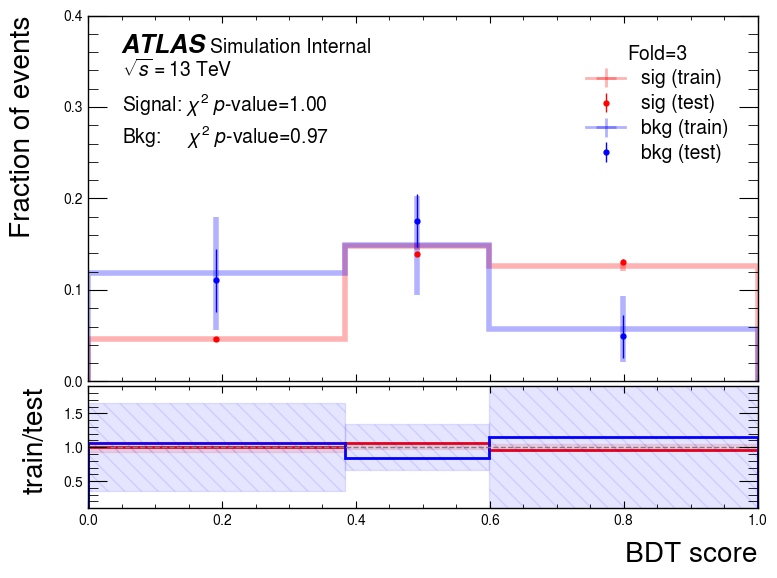

In [36]:
## !!!! KS test with fitted bins

# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 3
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)
#custom_bins = [0, 0.420, 0.639, 1]
custom_bins = [0, 0.383, 0.598, 1]     #older_binning


# Example dummy data and plots:
results_sig_fold_test = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])

"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=custom_bins, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=custom_bins, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=custom_bins, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=custom_bins, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=custom_bins)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)

print(bb)


print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)

#custom_bins = np.array([0, 0.420, 0.639, 1])
custom_bins = np.array([0, 0.383, 0.598, 1])     #older_binning


#bb_centers = (bb[:-1] + bb[1:]) / 2
bb_centers = (custom_bins[:-1] + custom_bins[1:]) / 2

mplhep.histplot(ratio_sig, custom_bins, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, custom_bins, histtype='step', ax=axes[1], color='blue', linewidth=2)

#bin_width = bb[1] - bb[0] 
#bin_width = custom_bins[1] - custom_bins[0]  # Update bin width based on custom bins
bin_widths = np.diff(custom_bins)  # Using np.diff to calculate the distance between bin edges
print(bin_widths)

    
# Plot the uncertainty band using custom bin centers and the clipped errors
for center, err, width in zip(bb_centers, clipped_errors_sig, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')

for center, err, width in zip(bb_centers, clipped_errors_bkg, bin_widths):
    axes[1].bar(center, 2 * err, width=width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_{fold}_Model7_85To70PerProcess_fittedOlderBins.png')

-----------------------------------------------
0.013299923948930047 1.831655246942656
0.010513528373326102 1.8545100632085794
11 10 10
Signal train histogram: [0.01329992 0.25648854 0.66018255 1.02199021 1.34205608 1.61266055
 1.8016985  1.83165525 1.30906896 0.15089905]
Signal test histogram: [0.01051353 0.24959099 0.67090189 1.03242881 1.35816076 1.64243745
 1.81312053 1.85451006 1.25394046 0.11439569]
Background train histogram: [0.11320107 1.2788172  1.48218589 1.87575086 1.59413781 1.5479064
 1.02716191 0.75099529 0.28727979 0.04256376]
Background test histogram: [0.18994735 0.96690565 1.92408689 1.64892377 1.43249788 1.48990053
 1.11999283 0.87619942 0.30260145 0.04894422]
-----------------------------------------------

Signal train errors: [0.00252301 0.01103736 0.01771776 0.02205334 0.02520896 0.02758221
 0.02911226 0.02930472 0.02476236 0.00837665]
Signal test errors: [0.00130721 0.00629309 0.01029633 0.01277011 0.01463749 0.01609366
 0.01690158 0.01706096 0.01399137 0.00418

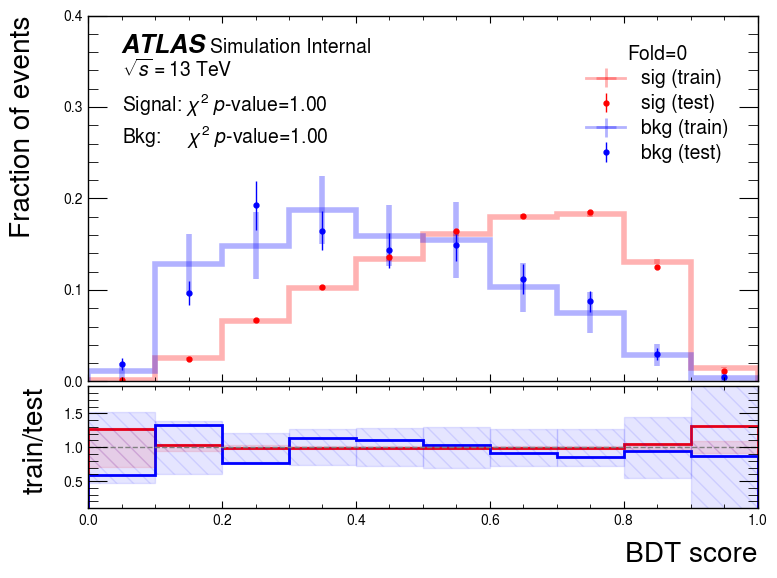

In [61]:
# Working code - Per fold. Change no. of folds
# Unweighted  - with corrected Sumw2()
# Normalized with auc
folds = 4
fold = 0
fig, axes = plt.subplots(nrows=2,ncols=1,gridspec_kw={'height_ratios': [3, 1]}, sharex=True)

# Example dummy data and plots:
results_sig_fold_test = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds == fold]
results_bkg_fold_test = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds == fold]
weights_sig_fold_test = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds == fold]
weights_bkg_fold_test = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds == fold]
y = np.concatenate([np.ones_like(results_sig_fold_test), np.zeros_like(results_bkg_fold_test)])
scores = np.concatenate([results_sig_fold_test, results_bkg_fold_test])
weights = np.concatenate([weights_sig_fold_test,weights_bkg_fold_test])

results_sig_fold_train = results_sig_85_reweighted[df_sig_85_reweighted['eventNumber']%folds != fold]
results_bkg_fold_train = results_bkg_85_reweighted[df_bkg_85_reweighted['eventNumber']%folds != fold]
weights_sig_fold_train = df_sig_85_reweighted['weight'][df_sig_85_reweighted['eventNumber']%folds != fold]
weights_bkg_fold_train = df_bkg_85_reweighted['weight'][df_bkg_85_reweighted['eventNumber']%folds != fold]
y = np.concatenate([np.ones_like(results_sig_fold_train), np.zeros_like(results_bkg_fold_train)])
scores = np.concatenate([results_sig_fold_train, results_bkg_fold_train])
weights = np.concatenate([weights_sig_fold_train,weights_bkg_fold_train])


"""
bc, bb = np.histogram(data1, weights=weights1, range=(-3,3), bins=10)
sumW2, bb = np.histogram(data1, weights=weights1**2, range=(-3,3), bins=10)
mplhep.histplot(bc,bb,yerr=np.sqrt(sumW2),density=True,label='10000 events, weight=0.1', histtype='errorbar')
"""
#bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, bins=np.linspace(0,1,11), density=True)


bc_sig_train, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train, range=(0,1), bins=10, density=True)
total_sig_train = len(results_sig_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_sig_fold_train, weights=weights_sig_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_train,bb,yerr=np.sqrt(sumW2), density=True, label='sig (train)', histtype='step', ax=axes[0], color='red', alpha=0.3, linewidth=4)
bc_sig_train_e = np.sqrt(sumW2)

bc_sig_test, bb = np.histogram(results_sig_fold_test,  weights=weights_sig_fold_test, range=(0,1), bins=10, density=True)
total_sig_test = len(results_sig_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_sig_fold_test, weights=weights_sig_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_sig_test,bb,yerr=np.sqrt(sumW2),density=True, label='sig (test)', histtype='errorbar', ax=axes[0], color='red', markersize=7)
bc_sig_test_e = np.sqrt(sumW2)

bc_bkg_train, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train, range=(0,1), bins=10, density=True)
total_bkg_train = len(results_bkg_fold_train) #np.sum(bc_sig_train)
sumW2, bb = np.histogram(results_bkg_fold_train, weights=weights_bkg_fold_train**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_train,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (train)', histtype='step', ax=axes[0], color='blue', alpha=0.3, linewidth=4)
bc_bkg_train_e = np.sqrt(sumW2)


bc_bkg_test, bb = np.histogram(results_bkg_fold_test,  weights=weights_bkg_fold_test, range=(0,1), bins=10, density=True)
total_bkg_test = len(results_bkg_fold_test) #np.sum(bc_sig_test)
sumW2, bb = np.histogram(results_bkg_fold_test, weights=weights_bkg_fold_test**2, range=(0,1), bins=10)
mplhep.histplot(bc_bkg_test,bb,yerr=np.sqrt(sumW2), density=True, label='bkg (test)', histtype='errorbar', ax=axes[0], color='blue', markersize=7)
bc_bkg_test_e = np.sqrt(sumW2)




print("-----------------------------------------------")
# Example check if data is within expected range
print(bc_sig_train.min(), bc_sig_train.max())
print(bc_sig_test.min(), bc_sig_test.max())

print(len(bb), len(bc_sig_train), len(bc_bkg_train))
bc_bkg_test = np.where(bc_bkg_test == 0, 1e-1, bc_bkg_test)


corr_factor_sig = np.sum(bc_sig_train)/np.sum(bc_sig_test)
chi2_sig, p_sig = chisquare(bc_sig_train, bc_sig_test*corr_factor_sig)
corr_factor_bkg = np.sum(bc_bkg_train)/np.sum(bc_bkg_test)
chi2_bkg, p_bkg = chisquare(bc_bkg_train, bc_bkg_test*corr_factor_bkg)


axes[0].set_xlim(0,1)
axes[0].set_ylim(0,4)

#scale_and_format_y_axis(axes[0], scale_factor=0.1)  # Adjust scale_factor as needed

# Create the FuncFormatter object
formatter = mtick.FuncFormatter(custom_formatter)

# Apply the custom formatter to the y-axis
axes[0].yaxis.set_major_formatter(formatter)
axes[0].yaxis.set_major_locator(mtick.MultipleLocator(1))   # removing this will lead to duplicate labels


axes[0].legend(title=F'Fold={fold}', loc='upper right')

#ax.set_xlabel('BDT score')
axes[0].set_ylabel('Fraction of events', labelpad=20)
mplhep.atlas.label('Internal', data=False, ax=axes[0])
axes[0].text(x=0.05, y=2.6,s=F'Signal: $\chi^2$ $p$-value={p_sig:.2f}\nBkg:     $\chi^2$ $p$-value={p_bkg:.2f}')
axes[0].tick_params(axis='both', labelsize=10)

print("Signal train histogram:", bc_sig_train)
print("Signal test histogram:", bc_sig_test)
print("Background train histogram:", bc_bkg_train)
print("Background test histogram:", bc_bkg_test)

print("-----------------------------------------------")




#y1 = bc_sig_train
#y1err = np.sqrt(sumW2) # calculated from sig train
#y2 = bc_sig_test
#y2err = np.sqrt(sumW2) # calculated from sig test






# Errors on histograms:
#bc_sig_train_e = np.sqrt(bc_sig_train/total_sig_train)*10  #np.sqrt(bc_sig_train)
#bc_sig_test_e = np.sqrt(bc_sig_test/total_sig_test)*10  #np.sqrt(bc_sig_test)
#bc_bkg_train_e = np.sqrt(bc_bkg_train/total_bkg_train)*10  #np.sqrt(bc_bkg_train)
#bc_bkg_test_e = np.sqrt(bc_bkg_test/total_bkg_test)*10  #np.sqrt(bc_bkg_test)





print("\nSignal train errors:", bc_sig_train_e)
print("Signal test errors:", bc_sig_test_e)
print("Background train errors:", bc_bkg_train_e)
print("Background test errors:", bc_bkg_test_e)

print("-----------------------------------------------")

ratio_sig = np.where(bc_sig_test == 0, 1, bc_sig_train / bc_sig_test)
ratio_bkg = np.where(bc_bkg_test == 0, 1, bc_bkg_train / bc_bkg_test)


print("\nSig ratio: ", ratio_sig)
print("Bkg ratio: ", ratio_bkg)


ratio_sig_e = np.sqrt((bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*(bc_sig_train/(1.0*bc_sig_test*bc_sig_test))*bc_sig_test_e*bc_sig_test_e+(1/(1.0*bc_sig_test))*(1/(1.0*bc_sig_test))*bc_sig_train_e*bc_sig_train_e)
ratio_bkg_e = np.sqrt((bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*(bc_bkg_train/(1.0*bc_bkg_test*bc_bkg_test))*bc_bkg_test_e*bc_bkg_test_e+(1/(1.0*bc_bkg_test))*(1/(1.0*bc_bkg_test))*bc_bkg_train_e*bc_bkg_train_e)

print("\nSig Ratio uncertainties per bin: ", ratio_sig_e)



# Ratio plot
#ratio_sig = bc_sig_train/bc_sig_test # np.divide(bc_sig_train, bc_sig_test, out=np.zeros_like(bc_sig_train), where=bc_sig_test != 0)
#ratio_bkg = bc_bkg_train/bc_bkg_test #  np.divide(bc_bkg_train, bc_bkg_test, out=np.zeros_like(bc_bkg_train), where=bc_bkg_test != 0)
#print(bb)
#print(ratio_sig)
#print(ratio_bkg)
#print(len(bb), len(ratio_sig), len(ratio_bkg))

# Clip errors and add padding
max_error = 100  # Example maximum error threshold
clipped_errors_sig = np.clip(ratio_sig_e, 0, max_error)
clipped_errors_bkg = np.clip(ratio_bkg_e, 0, max_error)

print("Clipped errors:", clipped_errors_sig)
print("Clipped errors:", clipped_errors_bkg)




bb_centers = (bb[:-1] + bb[1:]) / 2
#axes[1].plot(bb_centers, ratio_sig, 'o', label='Sig', color='red', linestyle='None', markersize=5)
#axes[1].plot(bb_centers, ratio_bkg, 'o', label='Bkg', color='blue', linestyle='None', markersize=5)
#axes[1].axhline(1,0,1,linestyle='--',color='grey')

mplhep.histplot(ratio_sig, bb, histtype='step', ax=axes[1], color='red', linewidth=2)
mplhep.histplot(ratio_bkg, bb, histtype='step', ax=axes[1], color='blue', linewidth=2)


# Plot with clipped errors
#axes[1].fill_between(bb_centers, y1=(ratio_sig + clipped_errors_sig), y2=(ratio_sig - clipped_errors_sig), alpha=0.2, color='red')
#axes[1].fill_between(bb_centers, y1=(ratio_bkg + clipped_errors_bkg), y2=(ratio_bkg - clipped_errors_bkg), alpha=0.2, color='blue')

#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), alpha=0.2, color='red', hatch='\\\\', zorder=1) 
#axes[1].fill_between(bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), alpha=0.2, color='blue', hatch='/', zorder=1) 


# Plot the ratio uncertainty bands with hatch styles
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='none', edgecolor='red', hatch='\\\\', zorder=1, linewidth=0.0)
#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_bkg), y2=(1 - clipped_errors_bkg), facecolor='none', edgecolor='#CCCCFF', hatch='///', zorder=1, linewidth=0.0)


#axes[1].fill_between(
#    bb_centers, y1=(1 + clipped_errors_sig), y2=(1 - clipped_errors_sig), facecolor='red', alpha=0.2, edgecolor='red', hatch='\\\\', zorder=1)

bin_width = bb[1] - bb[0] 
# Plot the uncertainty band in histogram style using bar
for center, err in zip(bb_centers, clipped_errors_sig):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='red', alpha=0.1, edgecolor='red', hatch='\\\\', align='center')
for center, err in zip(bb_centers, clipped_errors_bkg):
    axes[1].bar(center, 2 * err, width=bin_width, bottom=1 - err, color='blue', alpha=0.1, edgecolor='blue', hatch='\\\\', align='center')


#axes[1].set_dashes((5,2))

axes[1].axhline(1,0,1,linestyle='--',color='grey', linewidth=1)
axes[1].set_ylabel('train/test')
axes[1].set_xlabel('BDT score')
axes[1].tick_params(axis='both', labelsize=10)

axes[1].set_ylim(0.1,1.9)  # Adjust based on your ratio values
fig.tight_layout()
fig.subplots_adjust(hspace=0.02)
fig.savefig(f'Test_Train_Chi_Squared_Unweighted_10bins_{fold}_Model7_85To70PerProcess.png')

# ##############################

# ##############################

# Correlation plots

In [65]:
# Set of variables for WP85

feature_cols = ['jet_pt[:,0]',
                'jet_pt[:,1]', 
                'met_met',
                'ph_eta[:,0]', 
                'ph_eta[:,1]',
                'ph_pt[:,0]', 
                'ph_pt[:,1]',
                'ph_mlph_closest[:,0]', 
                'ph_mlph_closest[:,1]',
                'diph_M', 
                'event_nbjets85', 
                'dr_lep_ph0', 
                'dr_lep_ph1',
                'ph_conversion_type[:,1]', 
                'ph_conversion_type[:,0]',
                'ph_mphb85_closest[:,0]',
                'ph_mphb85_closest[:,1]',
                'm_AllObjects',
                'jet_tagWeightBin_DL1r_Continuous_Max',
                'dr_ph',
                'BDT_Output85To70Reweighted',
                  ]
                  


# Update the counter
global execution_count
execution_count += 1
print(f"This cell has been run {execution_count} times.")


This cell has been run 2 times.


In [66]:
cols = feature_cols+['eventNumber','weight','mcChannelNumber']
aliases = {'weight':'event_norm * weight_mc * weight_pileup * weight_leptonSF * weight_photonSF * weight_jvt * weight_bTagSF_DL1r_Continuous * event_lumi'}

In [67]:
df_bkg_prompt_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttyprodNLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttyprodNLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgamma_NLO_prod*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)

######################



df_bkg_prompt_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_prompt_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)',library="pd",aliases=aliases)



df_bkg_fakes_ttydecLO_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)',library="pd",aliases=aliases)
df_bkg_fakes_ttydecLO_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgamma_LO_dec*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)',library="pd",aliases=aliases)


######################



df_bkg_prompt_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_prompt_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)


df_bkg_fakes_Wyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)
df_bkg_fakes_Wyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700199)|(mcChannelNumber==700200)|(mcChannelNumber==700201))',library="pd",aliases=aliases)




######################

df_bkg_prompt_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_prompt_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*Vyy*.root:nominal'],expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


df_bkg_fakes_Zyy_85 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets85>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)
df_bkg_fakes_Zyy_70 = uproot.concatenate(['/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*Vyy*.root:nominal'],expressions=cols,cut='((ph_true_category[:,0]>=10)|(ph_true_category[:,1]>=10))&(event_nbjets70>=1)&((mcChannelNumber==700195)|(mcChannelNumber==700196)|(mcChannelNumber==700197))',library="pd",aliases=aliases)


In [68]:
# Reweight per process:
df_bkg_prompt_ttyprodNLO_85['weight'] *= len(df_bkg_prompt_ttyprodNLO_70)/len(df_bkg_prompt_ttyprodNLO_85)
df_bkg_fakes_ttyprodNLO_85['weight'] *= len(df_bkg_fakes_ttyprodNLO_70)/len(df_bkg_fakes_ttyprodNLO_85)
df_bkg_prompt_ttydecLO_85['weight'] *= len(df_bkg_prompt_ttydecLO_70)/len(df_bkg_prompt_ttydecLO_85)
df_bkg_fakes_ttydecLO_85['weight'] *= len(df_bkg_fakes_ttydecLO_70)/len(df_bkg_fakes_ttydecLO_85)
df_bkg_prompt_Wyy_85['weight'] *= len(df_bkg_prompt_Wyy_70)/len(df_bkg_prompt_Wyy_85)
#df_bkg_fakes_Wyy_85['weight'] *= len(df_bkg_fakes_Wyy_70)/len(df_bkg_fakes_Wyy_85)
df_bkg_prompt_Zyy_85['weight'] *= len(df_bkg_prompt_Zyy_70)/len(df_bkg_prompt_Zyy_85)
df_bkg_fakes_Zyy_85['weight'] *= len(df_bkg_fakes_Zyy_70)/len(df_bkg_fakes_Zyy_85)



In [71]:
df_sig_85 = uproot.concatenate('/eos/user/a/aghosal/SWAN_projects/BDT_model/ntuples_WP85/Model7_Injected_ForCorrelationWithBDTScore/Injected_dataset/*ttgammagamma*.root:nominal',expressions=cols,cut='(ph_true_category[:,0]<10)&(ph_true_category[:,1]<10)&(event_nbjets85>=1)',library="pd",aliases=aliases)


In [72]:
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_prompt_85_reweighted = pd.concat([df_bkg_prompt_ttyprodNLO_85, df_bkg_prompt_ttydecLO_85, df_bkg_prompt_Wyy_85, df_bkg_prompt_Zyy_85], ignore_index=False)
len(df_bkg_prompt_85_reweighted)
# Combine the two background datasets to form the WP85 reweighted background to WP70
df_bkg_fakes_85_reweighted = pd.concat([df_bkg_fakes_ttyprodNLO_85, df_bkg_fakes_ttydecLO_85, df_bkg_fakes_Wyy_85, df_bkg_fakes_Zyy_85], ignore_index=False)
len(df_bkg_fakes_85_reweighted)
df_bkg_85_reweighted = pd.concat([df_bkg_prompt_85_reweighted, df_bkg_fakes_85_reweighted], ignore_index=False)
df_sig_85_reweighted = df_sig_85

In [73]:
bkg_corr_matrix = df_bkg_85_reweighted[feature_cols].corr()
sig_corr_matrix = df_sig_85_reweighted[feature_cols].corr()

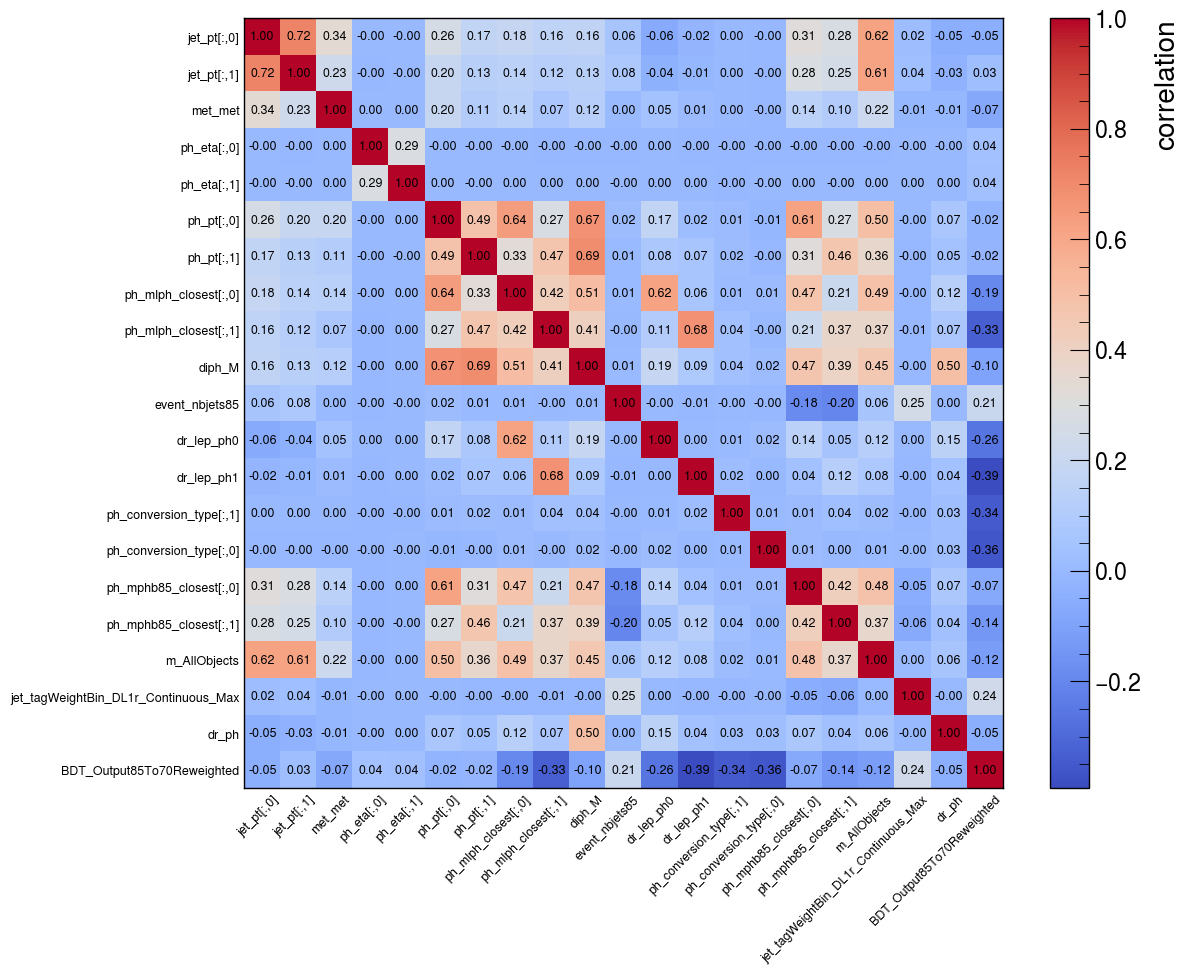

In [74]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = sig_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('sig_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


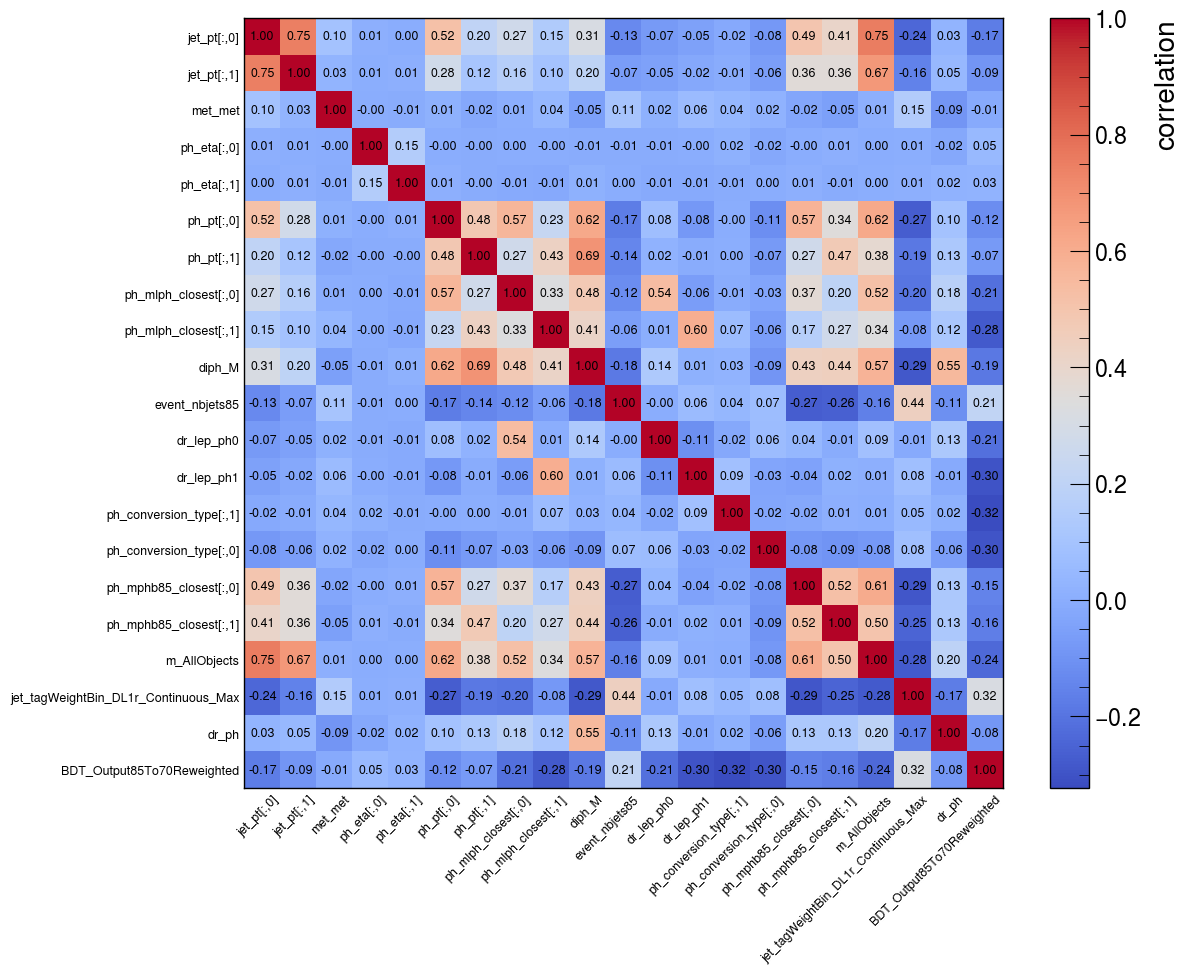

In [75]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = bkg_corr_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides


#plt.savefig('bkg_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')



In [76]:
corr_diff_matrix = sig_corr_matrix - bkg_corr_matrix

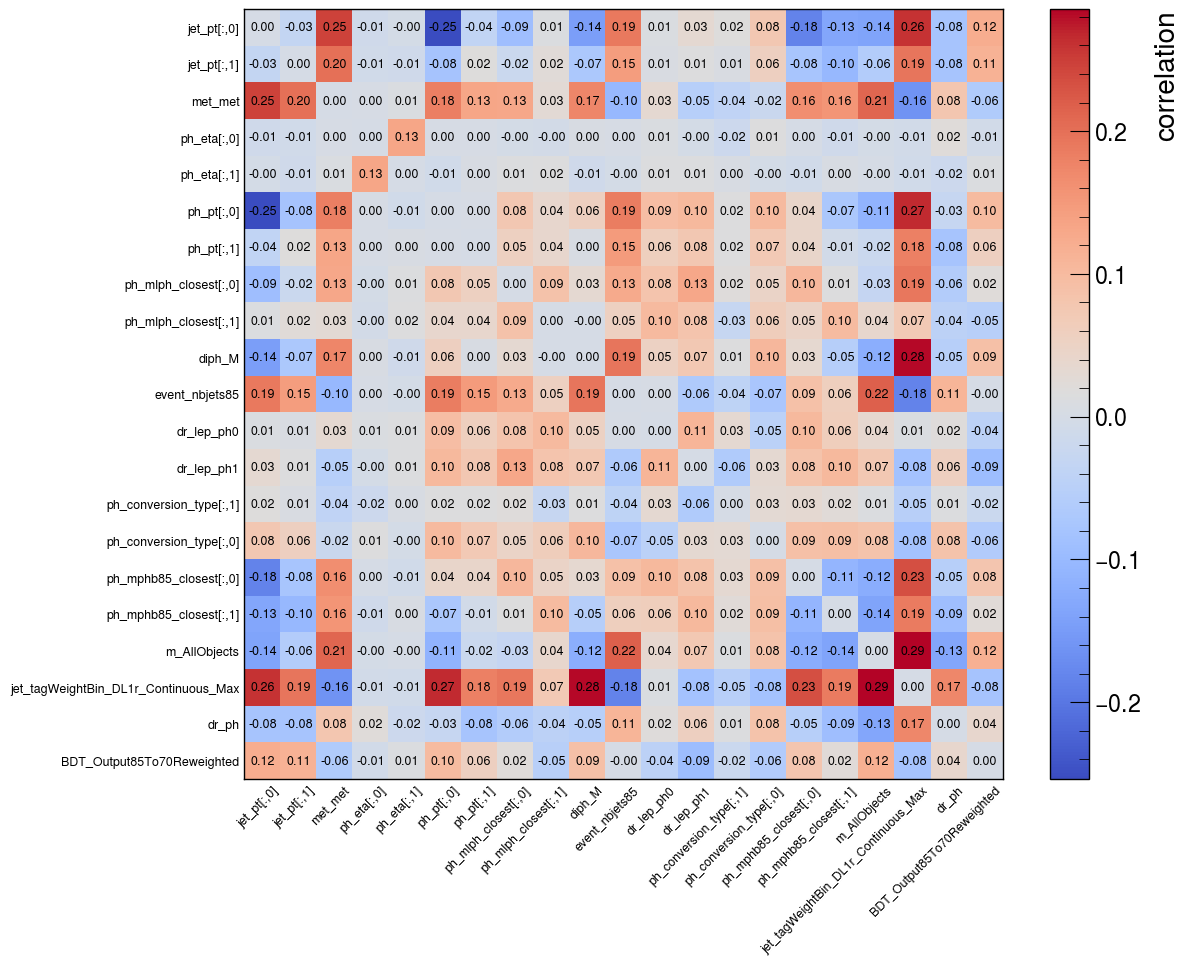

In [77]:
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = corr_diff_matrix.values  # Assuming bkg_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('diff_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')


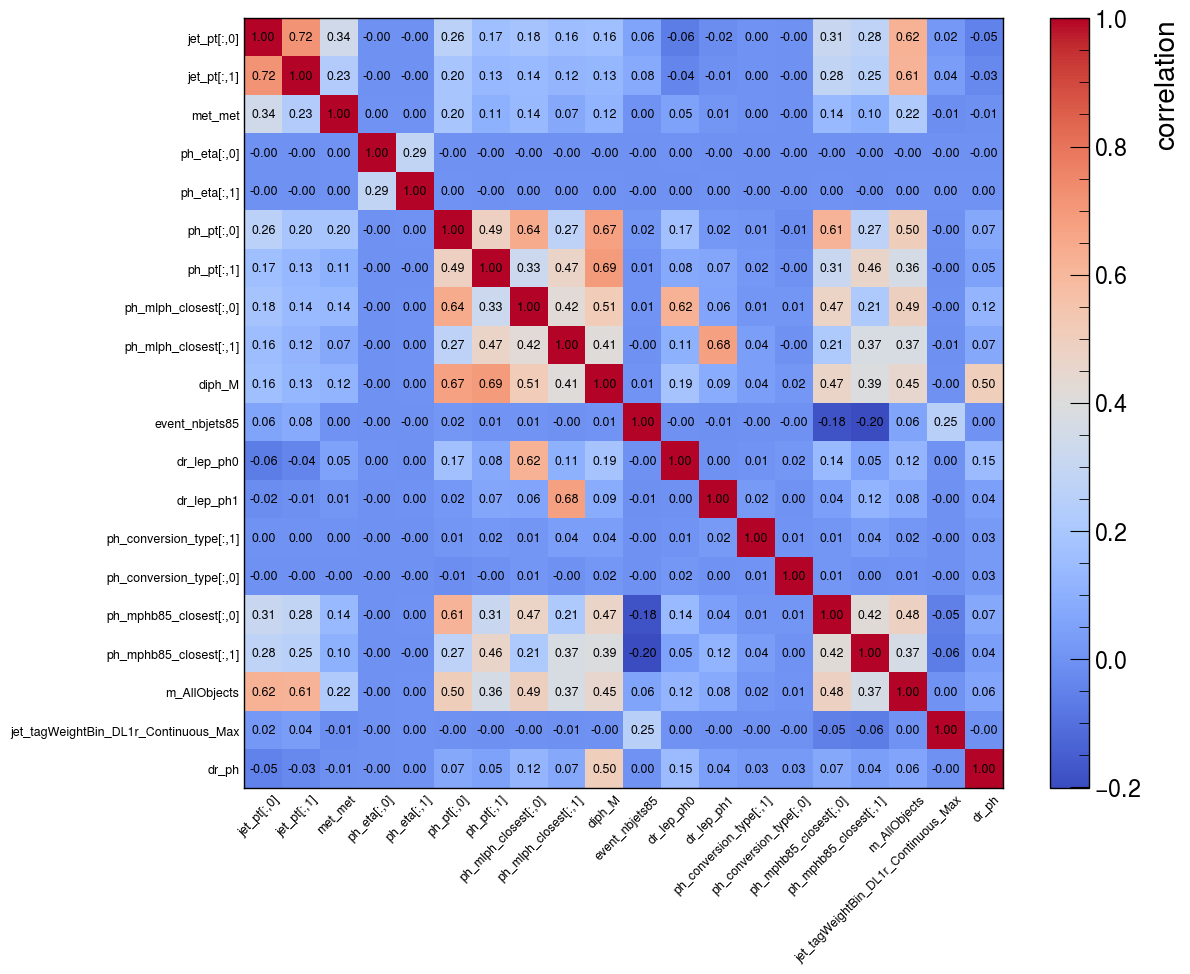

In [64]:
# Without BDT output
fig,ax = plt.subplots(figsize=(12, 10))  # Adjust width and height for desired size

# Create heatmap with coolwarm colormap and white background
corr = sig_corr_matrix.values  # Assuming sig_corr_matrix is your correlation matrix

# Create heatmap
heatmap = plt.imshow(corr, cmap='coolwarm', aspect='auto')

# Add colorbar
plt.colorbar(heatmap, label='correlation')

# Add white background to the plot area
ax.set_facecolor('white')  # 'gca' gets current axis

# Add annotations for each cell (replace '.1g' with desired format if needed)
for i in range(len(corr)):
    for j in range(len(corr[0])):
        plt.text(j, i, f"{corr[i, j]:.2f}", ha='center', va='center', fontsize=9)  # Adjust formatting

        
plt.xticks(rotation=45, ha='right', fontsize=9)  # Adjust rotation, alignment, and size
plt.yticks(fontsize=9)
ax.set_xticks(np.arange(len(feature_cols))+0.5,feature_cols)
ax.set_yticks(np.arange(len(feature_cols)),feature_cols)

plt.tick_params(which='both', bottom=False, top=False, left=False, right=False)  # Set visibility for all sides

#plt.savefig('sig_correlation_withBDTscore_heatmap_seaborn_large_white_Model6.pdf', dpi=500, bbox_inches='tight')
